# Q7. Temperature

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import metrics
import models
from data import CONDITIONS, ALL_CONDITIONS

W1117 17:31:45.594000 96294 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
COLORS = {'rf': 'tab:gray', 'cnn': 'tab:blue', 'resnet': 'tab:orange', 'wav2vec': 'tab:green'}
DATASETS = ['esc10', 'sc', 'sc_small']

WAV2VEC_ESC10 = True
WAV2VEC_SC = False
RUNS = (
    [('esc10', m) for m in models.MODELS if m != 'wav2vec' or WAV2VEC_ESC10]
    + [('sc_small', m) for m in models.MODELS]
    + [('sc', m) for m in models.MODELS if m != 'wav2vec' or WAV2VEC_SC]
)
NOISY = [c for c in CONDITIONS if c != 'clean']
METHODS = ['none', 'clean', 'pooled', 'oracle']

In [3]:
def fit_temperatures(d):
    names = ['clean'] + NOISY
    pooled = np.concatenate([d[f'val_{c}'] for c in names])
    y = np.tile(d['y_val'], len(names))
    return {'clean': metrics.fit_temperature(d['val_clean'], d['y_val']), 'pooled': metrics.fit_temperature(pooled, y)}

def group(condition):
    if condition == 'clean':
        return 'clean'
    return 'esc (unseen noise)' if condition.startswith('esc') else 'white/real (seen)'

rows = []
for dataset, model in RUNS:
    d = models.get_logits(dataset, model)
    t = fit_temperatures(d)
    for c in ALL_CONDITIONS:
        oracle = metrics.fit_temperature(d[f'val_{c}'], d['y_val'])
        for method, temperature in [('none', 1.0), ('clean', t['clean']), ('pooled', t['pooled']), ('oracle', oracle)]:
            m = metrics.evaluate(d[f'test_{c}'], d['y_test'], temperature)
            rows.append({'dataset': dataset, 'model': model, 'condition': c, 'group': group(c), 'method': method,
                         'temperature': temperature, 'acc': m['acc'], 'ece': m['ece_ts']})
res = pd.DataFrame(rows)
res[(res.condition == 'clean')].pivot_table(index=['dataset', 'model'], columns='method', values='temperature').round(2)

method            clean  none  oracle  pooled
dataset  model                               
esc10    cnn       0.64   1.0    0.64    1.80
         resnet    0.91   1.0    0.91    2.08
         rf        0.37   1.0    0.37    1.37
         wav2vec   1.09   1.0    1.09    1.95
sc       cnn       0.94   1.0    0.94    1.02
         resnet    1.38   1.0    1.38    1.39
         rf        0.38   1.0    0.38    0.53
sc_small cnn       0.40   1.0    0.40    1.53
         resnet    1.06   1.0    1.06    2.16
         rf        0.43   1.0    0.43    0.83
         wav2vec   0.76   1.0    0.76    0.98

In [4]:
summary = res.groupby(['dataset', 'group', 'method']).ece.mean().unstack('method')[METHODS]
summary.round(3)

method                        none  clean  pooled  oracle
dataset  group                                           
esc10    clean               0.122  0.027   0.316   0.027
         esc (unseen noise)  0.132  0.109   0.208   0.052
         white/real (seen)   0.282  0.319   0.213   0.068
sc       clean               0.110  0.009   0.046   0.009
         esc (unseen noise)  0.066  0.052   0.034   0.020
         white/real (seen)   0.053  0.048   0.026   0.020
sc_small clean               0.132  0.024   0.192   0.024
         esc (unseen noise)  0.092  0.127   0.073   0.022
         white/real (seen)   0.119  0.167   0.088   0.042

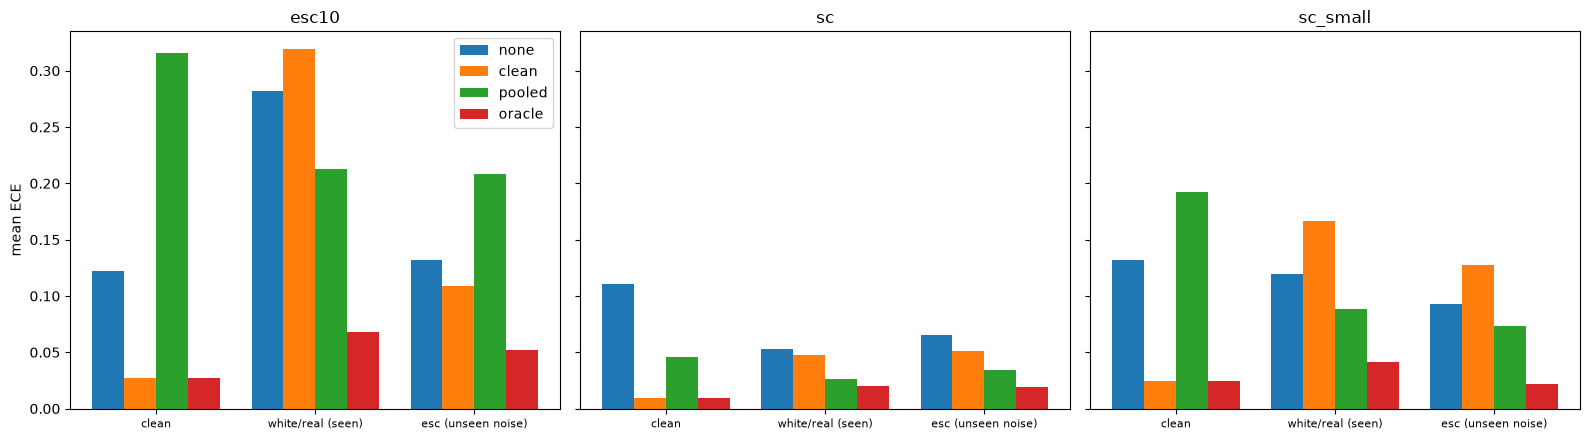

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
groups = ['clean', 'white/real (seen)', 'esc (unseen noise)']
for ax, dataset in zip(axes, DATASETS):
    part = summary.loc[dataset].reindex(groups)
    x = np.arange(len(groups))
    for i, method in enumerate(METHODS):
        ax.bar(x + i * 0.2 - 0.3, part[method], width=0.2, label=method)
    ax.set_xticks(x); ax.set_xticklabels(groups, fontsize=8); ax.set_title(dataset)
axes[0].set_ylabel('mean ECE'); axes[0].legend()
plt.tight_layout(); fig.savefig('../results/figures/' + 'q7_temperature' + '.png', dpi=150, bbox_inches='tight'); plt.show()

In [6]:
zero = res[res.condition.isin(['white_0', 'real_0', 'esc_0'])]
zero.pivot_table(index=['dataset', 'model', 'condition'], columns='method', values='ece')[METHODS].round(3)

method                       none  clean  pooled  oracle
dataset  model   condition                              
esc10    cnn     esc_0      0.045  0.143   0.208   0.044
                 real_0     0.362  0.499   0.172   0.061
                 white_0    0.794  0.861   0.549   0.098
         resnet  esc_0      0.186  0.213   0.079   0.057
                 real_0     0.543  0.567   0.270   0.056
                 white_0    0.774  0.793   0.491   0.098
         rf      esc_0      0.133  0.167   0.185   0.074
                 real_0     0.144  0.405   0.091   0.063
                 white_0    0.268  0.548   0.187   0.028
         wav2vec esc_0      0.206  0.179   0.051   0.043
                 real_0     0.521  0.493   0.246   0.059
                 white_0    0.714  0.686   0.414   0.052
sc       cnn     esc_0      0.039  0.050   0.039   0.038
                 real_0     0.016  0.023   0.015   0.037
                 white_0    0.033  0.019   0.039   0.017
         resnet  esc_0      0.104  0.049   0.046   0.011
                 real_0     0.081  0.029   0.030   0.025
                 white_0    0.047  0.019   0.022   0.018
         rf      esc_0      0.028  0.180   0.090   0.021
                 real_0     0.032  0.123   0.051   0.018
                 white_0    0.041  0.199   0.113   0.038
sc_small cnn     esc_0      0.117  0.371   0.039   0.022
                 real_0     0.187  0.437   0.096   0.032
                 white_0    0.105  0.365   0.065   0.113
         resnet  esc_0      0.226  0.208   0.047   0.016
                 real_0     0.263  0.245   0.090   0.004
                 white_0    0.262  0.245   0.104   0.008
         rf      esc_0      0.006  0.128   0.017   0.003
                 real_0     0.018  0.139   0.037   0.033
                 white_0    0.062  0.200   0.085   0.003
         wav2vec esc_0      0.051  0.125   0.056   0.037
                 real_0     0.129  0.219   0.135   0.069
                 white_0    0.171  0.268   0.177   0.086